# 07 · CTR predictor and hook-strength scorer (heuristic v0)

**Process.** Both models are transparent v0 heuristics, because no outcome labels exist yet. Real
CTR comes from the Reporting API, and that data was still empty (notebook 06). Each model has
three parts:

1. **Features**, extracted from the media:
   - for CTR: the title, plus faces (YuNet) and text (PP-OCR) on the thumbnail;
   - for the hook: the first 15 s of a clip, i.e. lead silence, speech pace, the opening sentence
     and direct address (spaCy).
2. **Sub-scores in [0, 1]** from piecewise-linear shapes over the scored features.
3. **A weighted sum × 100.**

Many more features are **stored with weight 0** (`ZERO_WEIGHT_FEATURES`), so that a trained version
can learn from them later without re-extracting anything.

| | |
|---|---|
| Report | §3 *CTR Predictor and Hook-Strength Scorer*; §4 *CTR Predictor and Hook Scorer* |
| Code | `backend/app/ctr/` (`features.py`, `detectors.py`, `scorer.py`), `backend/app/hook/` (`features.py`, `nlp.py`, `scorer.py`) |
| Decisions | 0019 (CTR heuristic v0), 0020 (hook heuristic v0) |

Without outcome labels the models are checked **for behaviour**: is the score reproducible from
the stored features, which sub-scores actually vary, and which features carry the ranking. Titles
and transcript text are not printed (0026 §3).

In [1]:
from yts_nb import *  # first: puts backend/ on sys.path
from app.ctr import scorer as ctr_scorer
from app.ctr.features import ThumbnailFeatures, TitleFeatures
from app.hook import scorer as hook_scorer
from app.hook.features import HookFeatures

print("hook weights:", hook_scorer.WEIGHTS, "| shapes:", hook_scorer.SHAPES)
print("hook framing:", hook_scorer.FRAMING, "| address:", hook_scorer.ADDRESS_SCORES, "2+ ->", hook_scorer.ADDRESS_MANY)
print("CTR weights:", ctr_scorer.WEIGHTS, "| face count:", ctr_scorer.FACE_COUNT_SCORES, "3+ ->", ctr_scorer.FACE_COUNT_MANY)

hook weights: {'start': 0.3, 'pace': 0.25, 'framing': 0.25, 'address': 0.2} | shapes: {'start': [(0.3, 1.0), (2.0, 0.0)], 'pace': [(1.0, 0.0), (2.3, 1.0), (3.8, 1.0), (5.0, 0.6)]}
hook framing: {'question': 1.0, 'curiosity': 0.7, 'none': 0.3} | address: {0: 0.3, 1: 0.8} 2+ -> 1.0
CTR weights: {'title_length': 0.35, 'faces': 0.3, 'face_size': 0.2, 'text_coverage': 0.15} | face count: {0: 0.2, 1: 0.9, 2: 1.0} 3+ -> 0.9


## 1. Hook scorer: every stored clip

In [2]:
hooks = await sql("""
    select h.clip_id, c.upload_id, c.rank, c.score as relevance_peak, h.score as hook,
           h.feature_vector -> 'features' as features, h.feature_vector -> 'sub_scores' as sub_scores,
           h.feature_vector ->> 'language' as language
    from hook_scores h join clips c on c.id = h.clip_id
""")
sub = pd.DataFrame(list(hooks.sub_scores))
print(f"{len(hooks)} clips from {hooks.upload_id.nunique()} episodes; hook score {hooks.hook.min():.1f}–{hooks.hook.max():.1f}, "
      f"median {hooks.hook.median():.1f}")

290 clips from 58 episodes; hook score 57.6–100.0, median 82.5


**Reproducibility.** Each stored score is recomputed from its stored features with the current
`hook.scorer.score`. A difference would mean the code and the stored data have drifted apart.

In [3]:
fields = set(HookFeatures.__dataclass_fields__)
rescored = [hook_scorer.score(HookFeatures(**{k: v for k, v in f.items() if k in fields})) for f in hooks.features]
diff = np.abs(np.array([r.score for r in rescored]) - hooks.hook.values)
same_sub = all(r.sub_scores == s for r, s in zip(rescored, hooks.sub_scores))
print(f"max |recomputed − stored| = {diff.max():.3f}; identical sub-scores: {same_sub}")

max |recomputed − stored| = 0.000; identical sub-scores: True


In [4]:
weighted = sub.mul(pd.Series(hook_scorer.WEIGHTS)) * 100
summary = pd.DataFrame({
    "weight": pd.Series(hook_scorer.WEIGHTS),
    "share at 1.0": (sub == 1.0).mean(),
    "distinct values": sub.nunique(),
    "std of points": weighted.std(),
})
summary["share of score variance"] = weighted.cov().sum() / weighted.sum(axis=1).var()
summary.round(3)

,weight,share at 1.0,distinct values,std of points,share of score variance
address,0.20,0.486,3,6.02,0.328
framing,0.25,0.248,3,7.54,0.537
pace,0.25,0.714,28,3.61,0.136
start,0.30,1.000,1,0.00,0.000


The last column splits the variance of the total score among the sub-scores: the covariance of
each weighted sub-score with the total, divided by the total's variance. It says which parts
actually rank the clips.

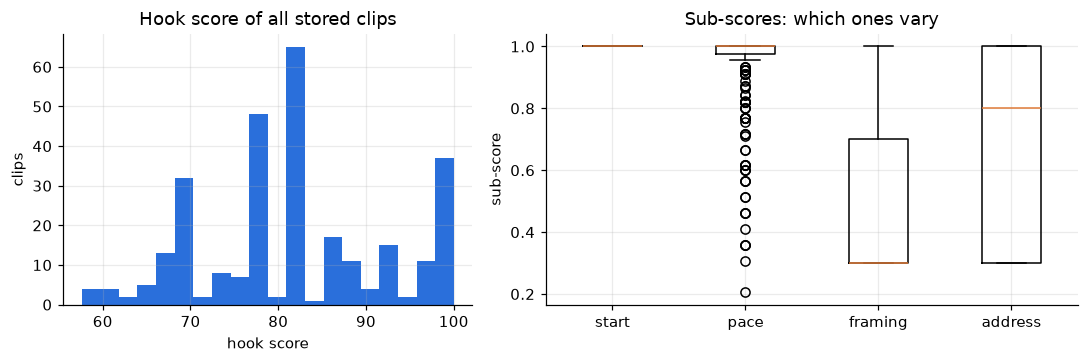

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].hist(hooks.hook, bins=20, color=COLORS[0])
axes[0].set(xlabel="hook score", ylabel="clips", title="Hook score of all stored clips")
order = ["start", "pace", "framing", "address"]
axes[1].boxplot([sub[k] for k in order], tick_labels=order)
axes[1].set(ylabel="sub-score", title="Sub-scores: which ones vary")
plt.tight_layout()
plt.show()

In [6]:
f = pd.DataFrame(list(hooks.features))
print(f"lead silence: {(f.lead_silence_s <= 0.3).mean():.0%} of clips at ≤ 0.3 s (sub-score 1.0)")
print(f"opening sentence: question {f.first_is_question.mean():.0%}, curiosity cue {(f.first_curiosity > 0).mean():.0%}")
print(f"direct address (second person + imperatives) in the first 15 s: "
      f"{((f.second_person + f.imperatives) > 0).mean():.0%} of clips")
r = np.corrcoef(hooks.hook, hooks.relevance_peak)[0, 1]
print(f"Pearson(hook score, relevance peak of the same clip) = {r:.2f}")

lead silence: 100% of clips at ≤ 0.3 s (sub-score 1.0)
opening sentence: question 25%, curiosity cue 13%
direct address (second person + imperatives) in the first 15 s: 71% of clips
Pearson(hook score, relevance peak of the same clip) = -0.07


**Reading, compared with the report's dry run on 25 clips of 5 episodes.**
- The dry run gave scores of 68.5–100. Over all 290 stored clips, the range is wider (see above),
  as expected from a larger sample.
- The *start* sub-score (lead silence, "dead air") is 1.0 for every clip, as in the report. The Shorts generator cuts
  at the start of a sentence, so on this channel it does not separate clips.
- The ranking is carried by **framing** (how the clip opens) and **direct address**. Direct address
  mostly counts the hosts talking to each other rather than to the viewer, a limitation the report
  names.
- The hook score is nearly independent of the relevance peak. It measures how a clip *opens*, not
  how good its content is, so the two signals complement each other.

## 2. CTR predictor

In [7]:
ctr = await sql("""
    select upload_id, source, partial, predicted_score, candidate_thumbnail_path is not null as has_thumbnail,
           features
    from ctr_predictions order by id
""")
print(ctr.groupby(["upload_id", "has_thumbnail"]).agg(candidates=("source", "size"), scored=("predicted_score", "count")).to_string())
ctr_jobs = await sql("select upload_id, status from jobs where tool_type = 'ctr'")
print("CTR jobs:", ctr_jobs.to_dict("records"))
scored = ctr[ctr.predicted_score.notna()].copy()
re_scores = []
for feats in scored.features:
    t = TitleFeatures(**feats["title"])
    th = ThumbnailFeatures(**{k: feats["thumbnail"][k] for k in ThumbnailFeatures.__dataclass_fields__}) if feats.get("thumbnail") else None
    re_scores.append(ctr_scorer.score(t, th))
scored["recomputed"] = [s.score for s in re_scores]
print(f"max |recomputed − stored| = {np.abs(scored.recomputed - scored.predicted_score).max():.3f}")
pd.DataFrame([{"candidate": i + 1, "score": s.score, **{f"sub_{k}": v for k, v in s.sub_scores.items()},
               "face_count": feats["thumbnail"]["face_count"], "largest_face_area": feats["thumbnail"]["largest_face_area"],
               "text_area": feats["thumbnail"]["text_area"], "title_chars": feats["title"]["title_chars"]}
              for i, (s, feats) in enumerate(zip(re_scores, scored.features))]).round(3)

                         candidates  scored
upload_id has_thumbnail                    
1         False                   5       0
2         True                    5       5
63        False                   5       0
CTR jobs: [{'upload_id': 2, 'status': 'succeeded'}]
max |recomputed − stored| = 0.000


,candidate,score,sub_title_length,sub_faces,sub_face_size,sub_text_coverage,face_count,largest_face_area,text_area,title_chars
0,1,96.6,1.000,1.0,0.831,1.000,2,0.083,0.159,50
1,2,79.6,0.914,1.0,0.131,1.000,2,0.013,0.087,37
2,3,81.8,1.000,0.9,0.408,0.775,1,0.041,0.005,48
3,4,80.9,1.000,0.9,0.363,0.774,1,0.036,0.005,47
4,5,76.2,0.971,1.0,0.132,0.635,2,0.013,0.356,39


**Reading.**
- The CTR tool was run once, on one episode: five title + thumbnail candidates, all scored. The
  other ten rows are candidates imported from show notes that were never scored. Had they been
  scored without a thumbnail, they would be title-only `partial` scores (decision 0019).
- On the five scored candidates, the title-length sub-score is near 1 for every title. The
  differences come from the thumbnail: mostly the **size of the largest face**, then the text
  coverage.
- The report notes that the channel's thumbnails are mostly single-camera close-ups with one face,
  so the face-count dimension varies less than expected. Five candidates are a behaviour check,
  not an evaluation.

## Summary

- Both heuristics are **reproducible**: each stored score is recomputed exactly from its stored
  features.
- The analysis of the sub-scores shows which parts rank the clips (framing, address) and which do
  not (lead silence). This is the evidence for what a trained version should learn once real CTR
  and retention labels arrive.
- Limitation: no outcome labels exist, so neither model has been validated against real
  performance.